# IS4487 Week 10 - Assignment

### Outline

Our Goals with this Project:

1. Import and review the data
2. Perform EDA and Clean Data
3. Fit a model
4. Test the accuracy of the model
6.  Use the model to predict on a new dataset (without the target)

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Business Context AdviseInvest
You work on a small team of data analysts at AdviseInvest, a venture-backed startup. The Director of Sales at AdviseInvest has approached your team asking for help solving a staffing problem.

### The Company
The company's mission is to provide tools and support to help ordinary people gain control of their personal finances. The company leverages technology to provide affordable financial advice to a national client base.

Customers who reach AdviseInvest's website go through five steps:

- Open an account.
- Complete a customer profile form with basic information about their background and finances.
- Schedule a free phone conversation with a sales representative during a 1-hour window of time.
- Attend the free phone conversation.
- Buy a financial plan.
- There are three types of financial plans: Beginner, Intermediate, and Advanced. Each is sold at a different price, and there are varying degrees of personalization. After a customer purchases a financial plan, the customer is assigned a financial planner who helps determine the customer's goals and advises the customer on spending decisions.

### The Problem
Some customers are lost at each stage of the process. Steps 3 and 4 are particularly challenging because approximately 50% of those who schedule a phone conversation fail to pick up the call. This leads to inefficiencies from a staffing perspective.

AdviseInvest has 4 sales reps on staff during each particular 1-hour window. Each of the 4 reps is assigned 2 prospective customers per hour, which means that the company schedules a total of 8 phone calls per hour. The calls are outgoing: sales reps call customers who scheduled a phone conversation during that hour window.

Unfortunately, as noted above, many of the customers who scheduled a call do not answer. As a consequence, sales reps are often left underutilized. Moreover, they are underutilized unevenly. For example, it is possible that one sales rep will not do any sales calls during that hour, whereas another will be busy the entire hour with two calls. Sales reps have nothing to do when customers do not answer the scheduled phone call.

### AdviseInvest Data Dictionary


| Variable | Description | Type | Code |
|:---|:---|:---|:---|
| customer_id | Unique customer identifier | Numeric | |
| Answered | Customer response | Binary | 0: customer did not answer scheduled call; 1: customer answered scheduled call |
| Income | Customer income in US dollars | Numeric | |
| Female | Customer gender | Binary | 0: male; 1: female |
| Age | Age in years | Numeric | |
| Job | Nature of job | Categorical | 0 : unemployed; 1 : entry level position; 2 : midlevel position; 3 : management/ self-employed/ highly qualified employee/ officer |
| Num_dependents | Number of people for whom the customer provides maintenance | Numeric | |
| Rent | Customer rents | Binary | 0: no; 1: yes |
| Own_res | Customer owns residence | Binary | 0: no; 1: yes |
| New_car | Recent new car purchase | Binary | New car purchase in the last 3 months: 0: no, 1: yes |
| Chk_acct | Checking account status | Categorical | 0 : no checking account; 1: checking < 200 USD; 2 : 200 < checking < 2000 USD; 3: 2000 < checking < 35000 USD; 4: >= 3500 USD |
| Sav_acct | Average balance in savings account | Categorical | 0 : no savings account; 1 : 100 <= savings < 500 USD; 2 : 500 <= savings < 2000 USD; 3 : 2000 < savings < 35000 USD; 4: >= 3500 USD |
| Num_accts | Number of accounts owned by customer | Numeric | |
| Mobile | Mobile phone | Binary | 0: customer provided non‐mobile phone for follow‐up call; 1: customer provided mobile phone for follow‐up call |
| Product | Type of product purchased after conversation with sales rep | Categorical | 0: customer did not answer call; 1: customer answered but did not purchase a product; 2: customer answered and purchased Beginner plan; 3: customer answered and purchased Intermediate plan; 4: customer answered and purchased Advanced plan |

### Load Libraries

Import the libraries you will need, such as:
- Pandas
- Sklearn (including DecisionTreeClassifier, RandomForestClassifier and GradingBoostingClassifier)
- Matplotlib


In [1]:
# Add code here 🔧
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier


## Step 1: Initial Data Understanding

### Do the following:
 - Import data from the AdviseInvest historical dataset into a dataframe (in GitHub go to the DataSets folder and look for `adviseinvest_historical_data.csv`).  The GitHub page is https://github.com/Stan-Pugsley/is_4487_base/tree/main/DataSets
 - Describe or profile the dataframe
 - Look for any outliers, missing values, or duplicates

In [3]:
# Add code here 🔧
url = 'https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/adviseinvest_historical_data.csv'

df = pd.read_csv(url)

df.head()
df.shape
df.info()
df.describe(include='all')
df.isnull().sum()
df.duplicated().sum()

numeric_cols = df.select_dtypes(include='number')
Q1 = numeric_cols.quantile(0.25)
Q3 = numeric_cols.quantile(0.75)
IQR = Q3 - Q1

outliers = (numeric_cols < (Q1 - 1.5 * IQR)) | (numeric_cols > (Q3 + 1.5 * IQR))
outliers.sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29504 entries, 0 to 29503
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   customer_id     29504 non-null  int64  
 1   answered        29504 non-null  int64  
 2   income          29504 non-null  int64  
 3   female          29504 non-null  object 
 4   age             29504 non-null  int64  
 5   job             29504 non-null  int64  
 6   num_dependents  29504 non-null  int64  
 7   rent            29504 non-null  int64  
 8   own_res         29504 non-null  int64  
 9   new_car         29502 non-null  float64
 10  chk_acct        29504 non-null  int64  
 11  sav_acct        29504 non-null  int64  
 12  num_accts       29504 non-null  int64  
 13  mobile          29504 non-null  int64  
 14  product         29504 non-null  int64  
dtypes: float64(1), int64(13), object(1)
memory usage: 3.4+ MB


,0
customer_id,0
answered,0
income,2241
age,1025
job,10688
num_dependents,4160
rent,6208
own_res,0
new_car,7104
chk_acct,0


### Reflection:
1.1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1.1. The job variable in the second output has the most missing values at 10,688.  

# Step 2: Data Preparation

## 2.1: Data Cleanup

### Do the following:
- 2.1 Check for and remove any outliers
- 2.2 Consider fixing any missing data (should you delete the record or impute the value?)
- 2.3 remove any variables, like customer_id, that are not helpful in predicting the target variable (hint: are there any variables that are available only AFTER the customer has answered, and wouldn't be useful in predicting?)
- 2.4 Clean up the data and put it in a new dataframe named "df_clean"


In [4]:
# Add code here 🔧
df_clean = df.drop_duplicates().copy()

cols = ['income', 'age', 'num_dependents', 'num_accts']
Q1, Q3 = df_clean[cols].quantile(.25), df_clean[cols].quantile(.75)
IQR = Q3 - Q1
df_clean = df_clean[~((df_clean[cols] < Q1 - 1.5*IQR) |
                      (df_clean[cols] > Q3 + 1.5*IQR)).any(axis=1)]

for col in df_clean.select_dtypes(include='number').columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

for col in df_clean.select_dtypes(include='object').columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

df_clean = df_clean.drop(columns=['customer_id', 'product'])

df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21245 entries, 129 to 28863
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   answered        21245 non-null  int64  
 1   income          21245 non-null  int64  
 2   female          21245 non-null  object 
 3   age             21245 non-null  int64  
 4   job             21245 non-null  int64  
 5   num_dependents  21245 non-null  int64  
 6   rent            21245 non-null  int64  
 7   own_res         21245 non-null  int64  
 8   new_car         21245 non-null  float64
 9   chk_acct        21245 non-null  int64  
 10  sav_acct        21245 non-null  int64  
 11  num_accts       21245 non-null  int64  
 12  mobile          21245 non-null  int64  
dtypes: float64(1), int64(11), object(1)
memory usage: 2.3+ MB


### Reflection:
2.5  Explain the steps that you took to clean outliers and missing data.  Why did you chose the approach that you used?

2.6  Which variables did you remove, and why?

### ✍️ Your Response: 🔧
2.5 I used IQR method to identify and remove possible outliers. I filled  missing numerical values with median because it's not as impacted by extreme values compared to the mean. I filled missing categorical values with mode as it represents the most frequent value. These methods were chosen to preserve as many customer records as possible instead of deleting whole rows.

2.6 I removed customer_id because it's only an identifier as product because it's an outcome of the marketing campaign.

## 2.2: Standardize variables

### Do the following:
 - Change "answered" to a boolean (true/false) type
 - Convert any variables that should be an integer into an integer

In [5]:
# Add code here 🔧
df_clean['answered'] = df_clean['answered'].astype(bool)
df_clean['new_car'] = df_clean['new_car'].astype(int)
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21245 entries, 129 to 28863
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   answered        21245 non-null  bool  
 1   income          21245 non-null  int64 
 2   female          21245 non-null  object
 3   age             21245 non-null  int64 
 4   job             21245 non-null  int64 
 5   num_dependents  21245 non-null  int64 
 6   rent            21245 non-null  int64 
 7   own_res         21245 non-null  int64 
 8   new_car         21245 non-null  int64 
 9   chk_acct        21245 non-null  int64 
 10  sav_acct        21245 non-null  int64 
 11  num_accts       21245 non-null  int64 
 12  mobile          21245 non-null  int64 
dtypes: bool(1), int64(11), object(1)
memory usage: 2.1+ MB


## 2.3 Convert variables

### Do the following:
- convert at least 3 variables to categorical where that data type is appropriate

In [6]:
# Add code here 🔧
df_clean[['female', 'job', 'rent']] = df_clean[['female', 'job', 'rent']].astype('category')
df_clean.dtypes

,0
answered,bool
income,int64
female,category
age,int64
job,category
num_dependents,int64
rent,category
own_res,int64
new_car,int64
chk_acct,int64


# Step 3: Exploratory Data Analysis (EDA)

### Do the following:
- Explore the relationships between the target and independent variables
- Create at least five charts to show the relationships, using different chart types that are approriate to the analysis
- Ensure that all charts are clearly labeled and formatted



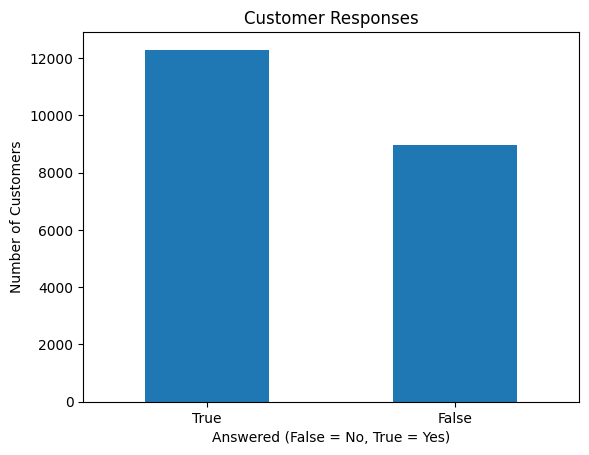

In [7]:
# Chart 3.1 🔧
df_clean['answered'].value_counts().plot(kind='bar')
plt.title('Customer Responses')
plt.xlabel('Answered (False = No, True = Yes)')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.show()


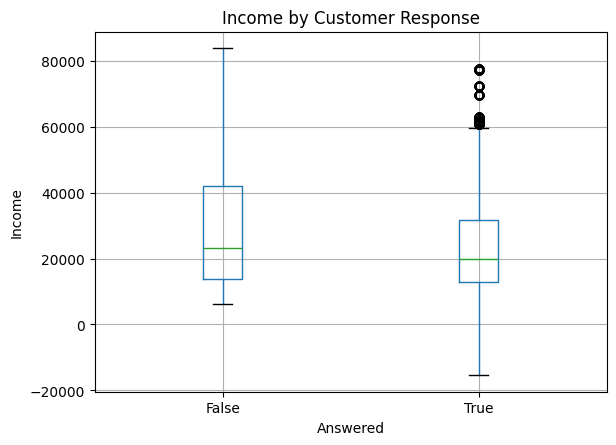

In [8]:
# Chart 3.2 🔧
df_clean.boxplot(column='income', by='answered')
plt.title('Income by Customer Response')
plt.xlabel('Answered')
plt.ylabel('Income')
plt.suptitle('')
plt.show()

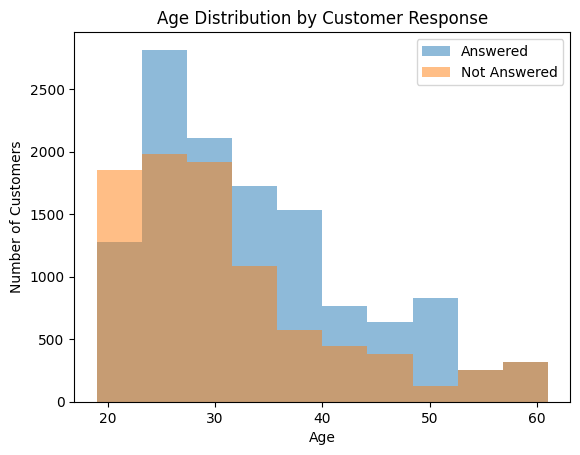

In [9]:
# Chart 3.3 🔧
plt.hist(df_clean[df_clean['answered'] == True]['age'], alpha=0.5, label='Answered')
plt.hist(df_clean[df_clean['answered'] == False]['age'], alpha=0.5, label='Not Answered')
plt.title('Age Distribution by Customer Response')
plt.xlabel('Age')
plt.ylabel('Number of Customers')
plt.legend()
plt.show()

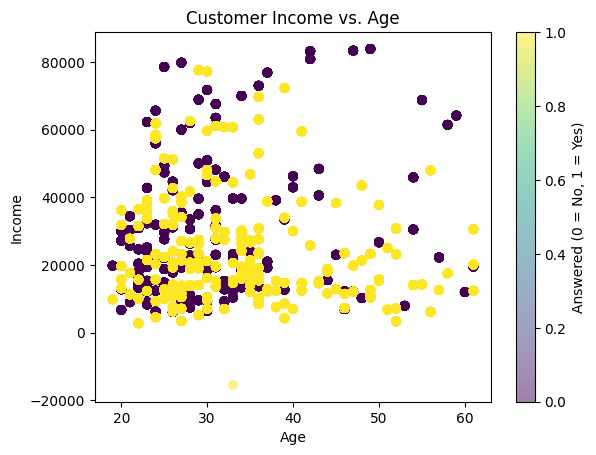

In [10]:
# Chart 3.4 🔧
plt.scatter(df_clean['age'], df_clean['income'],
            c=df_clean['answered'].astype(int), alpha=0.5)
plt.title('Customer Income vs. Age')
plt.xlabel('Age')
plt.ylabel('Income')
plt.colorbar(label='Answered (0 = No, 1 = Yes)')
plt.show()

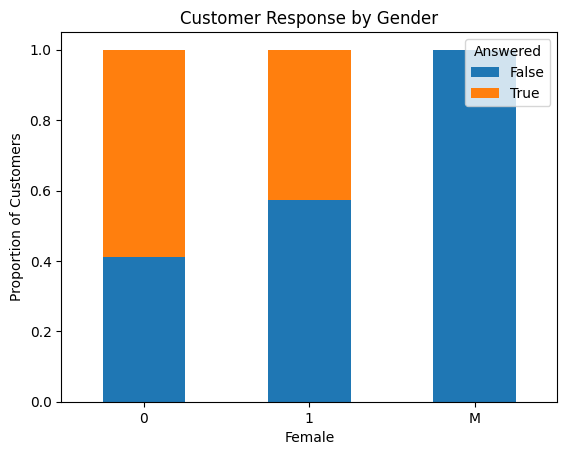

In [11]:
# Chart 3.5 🔧
pd.crosstab(df_clean['female'], df_clean['answered'], normalize='index').plot(kind='bar', stacked=True)
plt.title('Customer Response by Gender')
plt.xlabel('Female')
plt.ylabel('Proportion of Customers')
plt.legend(title='Answered')
plt.xticks(rotation=0)
plt.show()

### Reflection:
3.6. Which variables show the strongest relationship with the target variable?

3.7. Did you find any variables that have a weak relationship with the target variable?  Should they be removed?

### ✍️ Your Response: 🔧
3.6. Younger age demographics tends to answer the most as well as not answer the most.

3.7.  Most young people have low incomes but it's pretty dispersed as we move up and to the right of the scatterplot. I don't think this should be removed but not that it's not as important.

## Step 4: Modeling

Start with the baseline.  If we use no model at all, how good is our chance of predicting someone leaving?  Use a calculation to find the chances of someone leaving.

### Do the following:
4.1 Calculate the base probability of answering  

In [12]:
# Add code here 🔧
df_clean['answered'].mean()
df_clean['answered'].mean() * 100

np.float64(57.83478465521299)

## 4.2: Split the training and testing datasets

### Do the following:
- split df_clean using train_test_split function

Notes:
- all remaining variables except answered should be in the x variable
- answered is in the y variable


In [13]:
# Add code here 🔧
from sklearn.model_selection import train_test_split
X = df_clean.drop(columns=['answered'])
y = df_clean['answered']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

(16996, 12) (4249, 12)
(16996,) (4249,)


## 4.3: Create a Decision Tree

### Do the following:
- Create a tree
- Display (visualize) the tree

Notes:
- Use all available attributes (except those that were eliminated in step 3)
- It is recommended to use the type "entropy" and a max_depth of 4

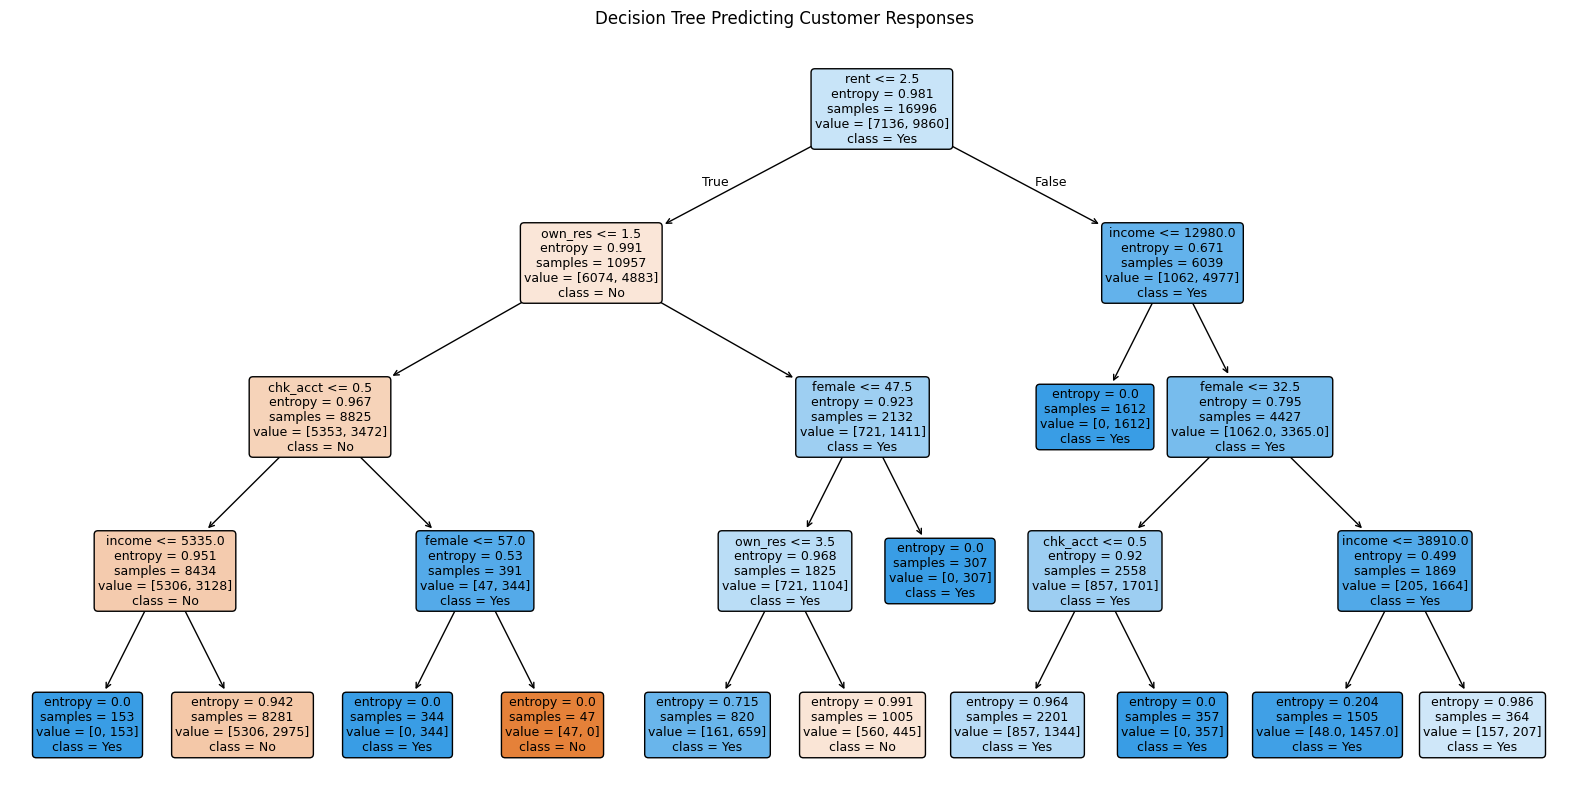

In [15]:
# Add code here 🔧
from sklearn.tree import DecisionTreeClassifier
X_train = pd.get_dummies(X_train, drop_first=True)
X_test = pd.get_dummies(X_test, drop_first=True)

X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
tree = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)
tree.fit(X_train, y_train)
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))
plot_tree(tree, feature_names=X.columns, class_names=['No', 'Yes'],
          filled=True, rounded=True, fontsize=9)
plt.title('Decision Tree Predicting Customer Responses')
plt.show()

## 4.4: Calculate the accuracy

This should be better than the base probability, or you have failed in your objective

### Do the following:
- Calculate the probability for your tree

In [16]:
# Add code here 🔧
from sklearn.metrics import accuracy_score

y_pred = tree.predict(X_test)
accuracy_score(y_test, y_pred)
print(f"Decision Tree Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")
print("Baseline:", y_test.value_counts(normalize=True).max() * 100)
print("Decision Tree:", accuracy_score(y_test, y_pred) * 100)

Decision Tree Accuracy: 72.21%
Baseline: 57.119322193457286
Decision Tree: 72.20522475876678


### Reflection:
1. What is the difference between the probability from the model compared to the base probability?
2. Is this difference a significant amount for the business?  

### ✍️ Your Response: 🔧
1. The difference is around 15.09 percentage points.

2. Yes, this is pretty significant.


## 4.5: Confusion Matrix

### Do the following
- Create a confusion matrix

This will show false positives, true positives, etc.

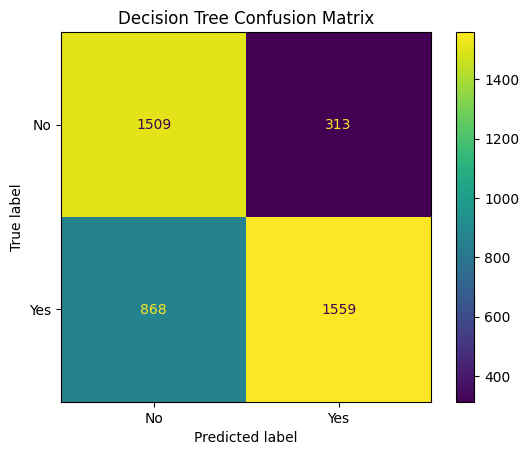

In [17]:
# Add code here 🔧
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No', 'Yes']).plot()
plt.title('Decision Tree Confusion Matrix')
plt.show()


Create a more visual, interpretable version of the matrix (hint - try using Seaborn Heatmap)

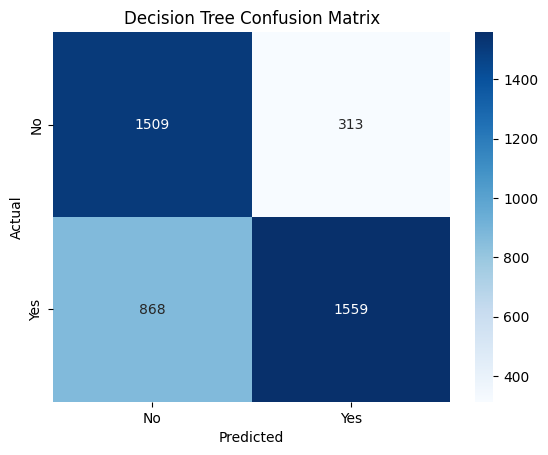

In [18]:
# Add code here 🔧
import seaborn as sns

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No', 'Yes'],
            yticklabels=['No', 'Yes'])

plt.title('Decision Tree Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

## 4.6 Check for Overfitting and Underfitting

A model may perform very well on its training data but poorly on new data. This is called **overfitting**. A model may also perform poorly on both training and test data. This is called **underfitting**.

Remember that we can evaluate fit with these guidelines:
- **Overfit:** Training accuracy is much higher than test accuracy.
- **Underfit:** Both training and test accuracy are low.
- **Balanced:** Training and test accuracy are fairly close, and test accuracy is meaningfully better than the baseline probability.


### Do the following:

- Calculate the accuracy of your decision tree on the training data.
- Compare it to the accuracy on the testing data.
- Calculate the difference between the two accuracy scores.

In [19]:
# Add code here 🔧
train_acc = tree.score(X_train, y_train)
test_acc = tree.score(X_test, y_test)

print(f"Training Accuracy: {train_acc * 100:.2f}%")
print(f"Testing Accuracy: {test_acc * 100:.2f}%")
print(f"Difference: {abs(train_acc - test_acc) * 100:.2f}%")

Training Accuracy: 72.68%
Testing Accuracy: 72.21%
Difference: 0.48%


### Reflection:
1. Does your model appear to be overfit, underfit, or reasonably balanced? Explain using the training and testing accuracy scores.
2. If the model is overfit, what changes could you make to simplify it?
3. If the model is underfit, what changes could you make to allow it to identify more patterns?
### ✍️ Your Response: 🔧
1. THe models seems to be balanced with only a difference of 0.48%. Th
2. If the model is overfit, I could limit the number of branches to prevent the model from learning too much detail from the training data.
3. I could increase the limit of branches so the model can learn more patterns in the data.

# Step 5: Evaluate the Model

**Assumptions**

One of the simplifying assumptions we will make in this project is that all the customers who answer the phone will purchase a product. (This assumption is actually verified by the data.) To model "answered" in this case is therefore equivalent to modeling "purchased."

There are costs and benefits in this case. We will assume that customers purchase a product for 100 dollars. This was the average cost of AdviseInvest products, according to the Director of Sales.  Also, as we learned in the interview, the agent time to make the sale is worth 25 dollars. Profit would therefore be \$75 dollars for an answered call and a purchase. In sum:

**Benefit**: True positive. The customer is predicted to answer, does answer, and purchases a product for 100 dollars for a profit of 100 - 25 = 75.

**Cost**: False positive. The customer is predicted to answer, but does not answer, so there is a loss of 25. (We assume the agent cannot schedule another call at the last minute, or spends the entire time slot trying to make the call.)

When you create a calculation you can use:
- True answered * 75 -> These people purchased
- False answered * 25 -> You can't schedule another call

For this exercise, we propose that customers who are not predicted to answer will not be called, so there would be no benefits and no costs for them.  

### Do the following:
Calculate the Profit Using the Model

In [25]:
# Add code here 🔧
default_profit = (y_test.sum() * 75) - ((len(y_test) - y_test.sum()) * 25)

print("Default Profit: $", default_profit)

Default Profit: $ 136475


In [20]:
# Add code here 🔧
tn, fp, fn, tp = cm.ravel()

profit = (tp * 75) - (fp * 25)

print("True Positives:", tp)
print("False Positives:", fp)
print("Total Profit: $", profit)

True Positives: 1559
False Positives: 313
Total Profit: $ 109100


## 5.2 Compare to the Default Profit

### Do the following:
- Calculate the profit (revenue - costs) that would be expected if all customers are called

Notes:
- We can consider this a baseline case for profit since it does not require a model
- In other words, to calculate profit in this baseline scenario treat the customers who answer as true positives treat the customers who do not answer as false positives.

In [21]:

all_profit = (y_test.sum() * 75) - ((len(y_test) - y_test.sum()) * 25)

model_profit = (tp * 75) - (fp * 25)

print("Profit from calling everyone: $", all_profit)
print("Profit from using the model: $", model_profit)
print("Difference in profit: $", model_profit - all_profit)

Profit from calling everyone: $ 136475
Profit from using the model: $ 109100
Difference in profit: $ -27375


### Reflection:
1. What is the difference in profit between calling all customers and calling customers that are recommended by the model?
2. Is this a significant amount for the business?  

### ✍️ Your Response: 🔧
1. The difference in profit is $27.4k.

2. This difference is a meaningful amount. Calling every customerfs generate $135.5k while following the decision model produces $109.1k.


## 5.3 Tune the Model

### Do the Following
- Create a new version of the tree with new parameters
- Calculate a new probability

Notes:
- Adjust the size or shape of the tree, then test the accuracy
- Keep changing these parameters until you end up with a tree with accuracy that is better than the initial model

In [22]:
# Add code here 🔧
tree2 = DecisionTreeClassifier(criterion='entropy', max_depth=6, random_state=42)
tree2.fit(X_train, y_train)

y_pred2 = tree2.predict(X_test)

print("New Accuracy:", accuracy_score(y_test, y_pred2) * 100)
print("Probability of answering:", tree2.predict_proba(X_test)[:, 1].mean() * 100)

New Accuracy: 75.92374676394445
Probability of answering: 57.75463064004762


## 5.4 Create a Random Forest Model

A random forest combines the predictions of many decision trees. Each tree uses a different random sample of the training data and considers a random subset of variables at each split. Combining the trees can produce a more stable prediction than relying on one tree.

### Do the following:
- Import and create a RandomForestClassifier model.
- Use at least 100 trees (n_estimators=100) and set random_state=42.
- Fit the model using the same training data used for the decision tree.
- Predict whether customers in the test data will answer.
- Calculate the test accuracy and display a confusion matrix.
- Create a feature-importance chart for the random forest.

Random Forest Accuracy: 100.0


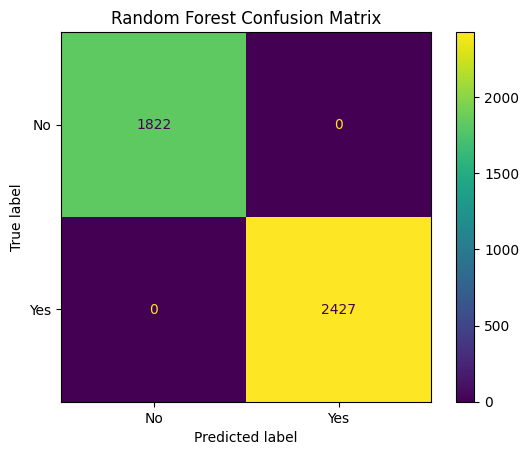

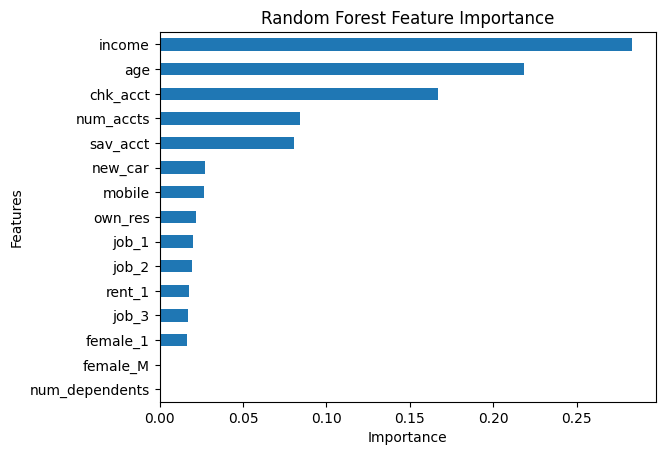

In [23]:
# Add code here 🔧
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

from sklearn.metrics import accuracy_score

rf_pred = rf.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, rf_pred) * 100)

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

rf_cm = confusion_matrix(y_test, rf_pred)

ConfusionMatrixDisplay(rf_cm, display_labels=['No', 'Yes']).plot()
plt.title('Random Forest Confusion Matrix')
plt.show()
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.Series(rf.feature_importances_, index=X_train.columns)
importance.sort_values().plot(kind='barh')

plt.title('Random Forest Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.show()


### Reflection:
1. Did the random forest have higher or lower test accuracy than your tuned decision tree?
2. Which variables were most important in the random forest? Were they the same variables that appeared near the top of your decision tree?

### ✍️ Your Response: 🔧
1. The random forest have a higher test accuracy of 100.0.
2. The income, age, and chk_acct. The only consistent variable across both models was the income.

### 5.5 Create a Gradient Boosting Model

Gradient boosting also combines many small trees, but it builds them in sequence. Each new tree attempts to improve the mistakes made by the earlier trees. This can create a strong predictive model, although its settings should be chosen carefully to avoid overfitting.

### Do the following:

- Import and create a GradientBoostingClassifier model.
- Start with n_estimators=100, learning_rate=0.1, max_depth=3, and random_state=42.
- Fit the model using the same training data.
- Predict whether customers in the test data will answer.
- Calculate test accuracy and display a confusion matrix.
- Create a feature-importance chart for the gradient boosting model.

Gradient Boosting Accuracy: 91.05671922805367


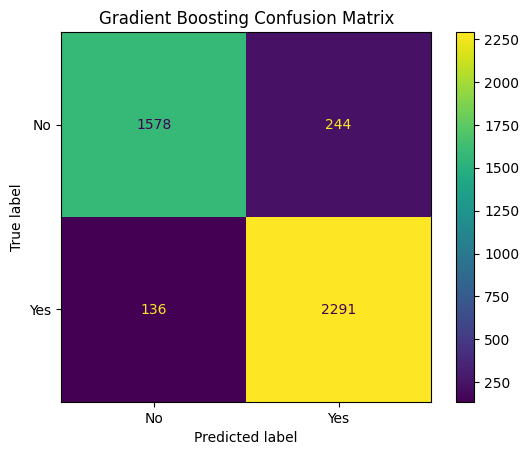

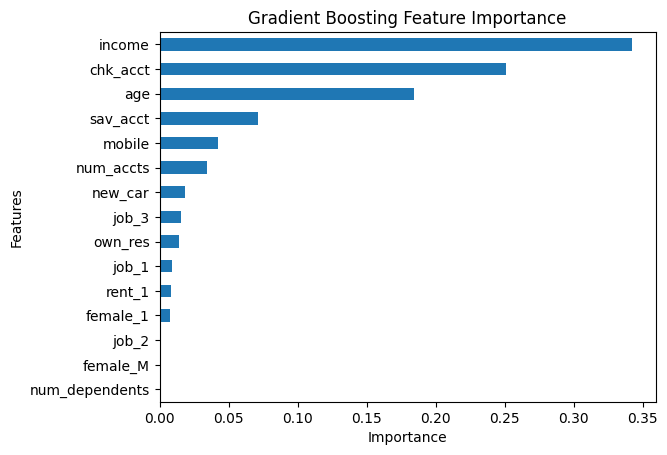

In [26]:
# Add code here 🔧
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)

gb.fit(X_train, y_train)
from sklearn.metrics import accuracy_score

gb_pred = gb.predict(X_test)

print("Gradient Boosting Accuracy:", accuracy_score(y_test, gb_pred) * 100)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

gb_cm = confusion_matrix(y_test, gb_pred)

ConfusionMatrixDisplay(gb_cm, display_labels=['No', 'Yes']).plot()
plt.title('Gradient Boosting Confusion Matrix')
plt.show()
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.Series(gb.feature_importances_, index=X_train.columns)

importance.sort_values().plot(kind='barh')
plt.title('Gradient Boosting Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.show()

### Reflection:

1. Which model had better test accuracy: the random forest or gradient boosting model?
2. In your own words, how does gradient boosting differ from a random forest?

### ✍️ Your Response: 🔧

1. The random forest is higher at 100.0 compared to the gradient's 91.06.
2. The trees are more independent and parallel in random forest while in gradient boosting it's more sequential as it corrects previous errors.


## 5.6 Compare Models Using Accuracy and Profit

Accuracy is useful, but AdviseInvest ultimately cares about staffing and profit. Compare your tuned decision tree, random forest, and gradient boosting models using both measures.

### Do the following:
- Create a table with one row for each model.
- Include each model's test accuracy, true positives, false positives, and estimated profit.
- Calculate model profit using the same business rules from Step 5:
- profit = (true positives × 75) - (false positives × 25)
- Create a bar chart comparing the test accuracy of the three models.
- Identify the model you would recommend for use on new customer data. Your choice should consider both accuracy and profit.

In [29]:
# Example structure; replace the values with your own calculations
tree_accuracy = accuracy_score(y_test, tree2.predict(X_test))
tree_tn, tree_fp, tree_fn, tree_tp = confusion_matrix(y_test, tree2.predict(X_test)).ravel()

rf_accuracy = accuracy_score(y_test, rf_pred)
rf_tn, rf_fp, rf_fn, rf_tp = rf_cm.ravel()

gb_accuracy = accuracy_score(y_test, gb_pred)
gb_tn, gb_fp, gb_fn, gb_tp = gb_cm.ravel()

tree_profit = tree_tp * 75 - tree_fp * 25
rf_profit = rf_tp * 75 - rf_fp * 25
gb_profit = gb_tp * 75 - gb_fp * 25
model_results = pd.DataFrame({
    'Model': ['Tuned Decision Tree', 'Random Forest', 'Gradient Boosting'],
    'Test Accuracy': [tree_accuracy, rf_accuracy, gb_accuracy],
    'True Positives': [tree_tp, rf_tp, gb_tp],
    'False Positives': [tree_fp, rf_fp, gb_fp],
    'Estimated Profit': [tree_profit, rf_profit, gb_profit]
})

model_results


,Model,Test Accuracy,True Positives,False Positives,Estimated Profit
0,Tuned Decision Tree,0.759237,1652,248,117700
1,Random Forest,1.000000,2427,0,182025
2,Gradient Boosting,0.910567,2291,244,165725


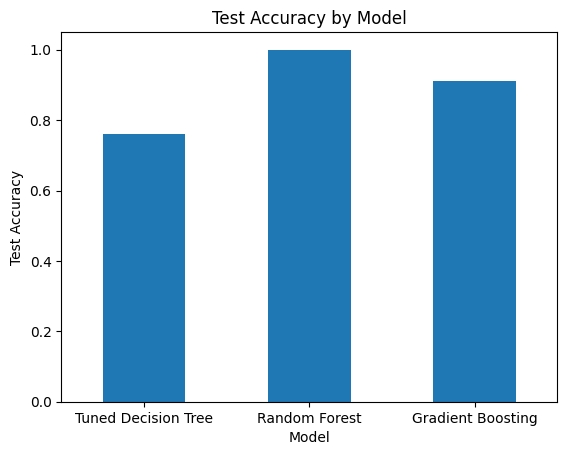

In [30]:
# Add code here 🔧
model_results.plot(x='Model', y='Test Accuracy', kind='bar', legend=False)

plt.title('Test Accuracy by Model')
plt.xlabel('Model')
plt.ylabel('Test Accuracy')
plt.xticks(rotation=0)
plt.show()

## 5.7 Apply the Best Model to New Customers

### Do the Following

- Import the "adviseinvest_new_customer_data.csv" file
- Copy and paste the applicable data cleanup and data-type conversion steps from 2.1 through 2.3.
- Make the new-customer variables match the columns used to train your models. If you used pd.get_dummies(), ensure that the new dataset has the same - dummy-variable columns as the training data.
- Using the model you recommended in Step 5.6, predict each customer's target variable by feeding the new customer data into the model.
- Predict the number of customers who will be yes/no for the target variable

In [32]:
# Add code here 🔧
new_df = pd.read_csv('https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/adviseinvest_new_customer_data.csv')

new_df.head()
new_clean = new_df.copy()

new_clean = new_clean.drop(columns=['customer_id', 'product'], errors='ignore')

for col in new_clean.select_dtypes(include='number').columns:
    new_clean[col] = new_clean[col].fillna(new_clean[col].median())

for col in new_clean.select_dtypes(include='object').columns:
    new_clean[col] = new_clean[col].fillna(new_clean[col].mode()[0])

new_clean['new_car'] = new_clean['new_car'].astype(int)

new_clean[['female', 'job', 'rent']] = new_clean[['female', 'job', 'rent']].astype('category')
new_X = pd.get_dummies(new_clean, drop_first=True)

new_X = new_X.reindex(columns=X_train.columns, fill_value=0)
best_model = rf

new_predictions = best_model.predict(new_X)
prediction_counts = pd.Series(new_predictions).value_counts()

print("Predicted No:", prediction_counts.get(False, 0))
print("Predicted Yes:", prediction_counts.get(True, 0))

Predicted No: 429
Predicted Yes: 571


### Reflection:

1. Which model produced the highest estimated profit? Was it also the most accurate model?
2. Why might a business select a model with slightly lower accuracy?
3. Which model would be easiest to explain to the Director of Sales? Which model would you recommend using?

### ✍️ Your Response: 🔧
 1. Random forest has the highest estimated profit and was the most accurate model
 2. A business may choose a model with slightly lower accuracy because it generates more profit or reduce costs.
 3. I think the decision tree just because it makes the most sense for me to understand visually.






# Step 6: Conclusion

### Reflection:
6.1: Did we improve our profit using the model?  

6.2: How could the model be utilized by the business?

### ✍️ Your Response: 🔧
6.1 Yes profit was improved using the random forest model. Profit decreased using the gradient.

6.2 Sales reps can use the model to identify and prioritize calling customers who are more likely to pick up rather than waste time on customers aren't going to answer. This allows energy and time to be more efficiently allocated and increase profitability.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [33]:
!jupyter nbconvert --to html "assignment_10_classification.ipynb"

[NbConvertApp] WARNING | pattern 'assignment_10_classification.ipynb' matched no files
This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file
    Equivalent to: [--JupyterApp.generate_config=True]
-y
    Answer yes to any questions instead of prompting.
    Equivalent to: [--JupyterApp.answer_yes=Tr